<a href="https://colab.research.google.com/github/josecano8910/vocalization-acoustics-replication/blob/main/notebooks/02_multimodal_hr_alignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

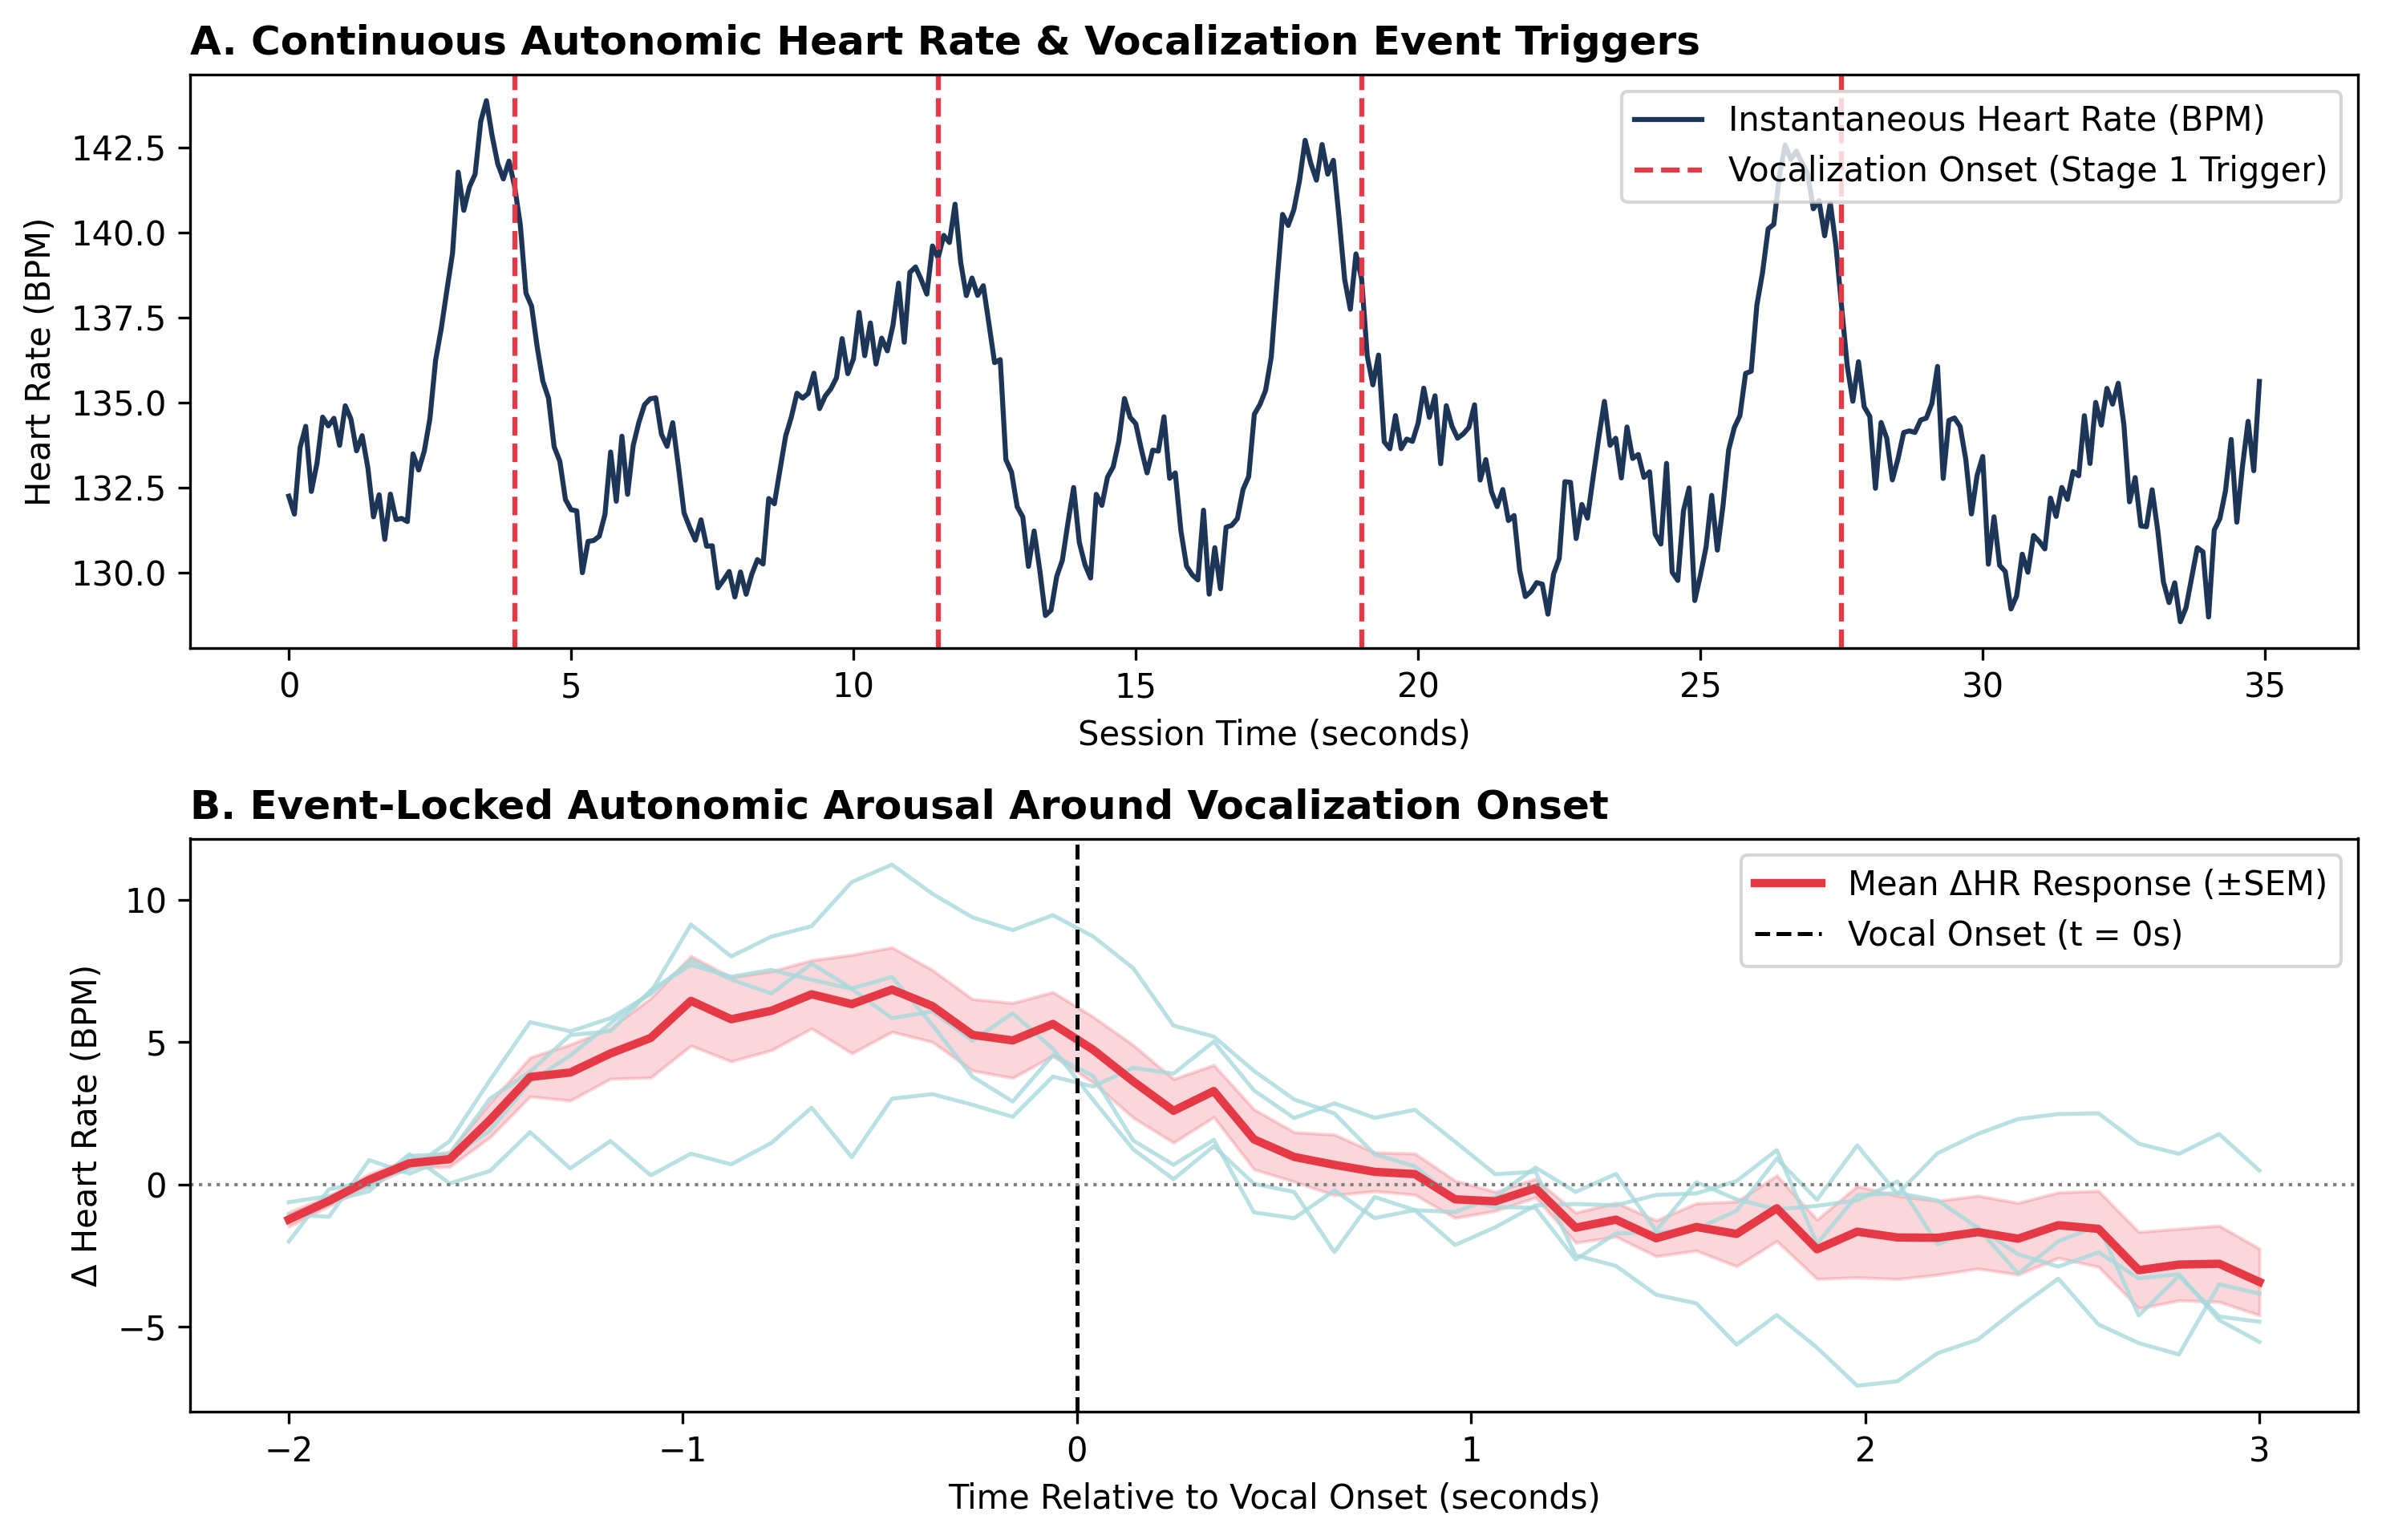

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def run_multimodal_hr_alignment():
    os.makedirs("figures", exist_ok=True)

    # 1. Stage 1 vocalization onset timestamps (in seconds)
    vocal_onsets = np.array([4.0, 11.5, 19.0, 27.5])

    # 2. Simulate a 35-second continuous Heart Rate (BPM) signal sampled at 10 Hz
    fs = 10
    duration = 35.0
    time = np.linspace(0, duration, int(duration * fs), endpoint=False)

    rng = np.random.default_rng(42)
    baseline_bpm = 132.0

    # Natural respiratory sinus arrhythmia + minor noise
    rsa_wave = 2.5 * np.sin(2 * np.pi * 0.35 * time)
    noise = rng.normal(0, 0.8, size=time.shape)
    hr_signal = baseline_bpm + rsa_wave + noise

    # Inject autonomic arousal bump starting ~0.5s before each vocal onset
    for onset in vocal_onsets:
        arousal_bump = 8.5 * np.exp(-0.5 * ((time - (onset - 0.5)) / 0.9) ** 2)
        hr_signal += arousal_bump

    # 3. Event-Locked Epoching: Slice [-2.0s to +3.0s] around each vocal onset (t = 0)
    pre_sec, post_sec = 2.0, 3.0
    epoch_time = np.linspace(-pre_sec, post_sec, int((pre_sec + post_sec) * fs))
    epochs = []

    for onset in vocal_onsets:
        start_idx = int((onset - pre_sec) * fs)
        end_idx = start_idx + len(epoch_time)
        epoch_slice = hr_signal[start_idx:end_idx]

        baseline_val = np.mean(epoch_slice[:5])
        epochs.append(epoch_slice - baseline_val)

    epochs = np.array(epochs)
    mean_response = np.mean(epochs, axis=0)
    sem_response = np.std(epochs, axis=0) / np.sqrt(len(epochs))

    # 4. Plot Continuous Stream (axes[0]) + Event-Locked Autonomic Response (axes[1])
    fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), dpi=300)

    # Panel A: Full Session Heart Rate + Vocalization Event Markers
    axes[0].plot(time, hr_signal, color="#1d3557", linewidth=1.5, label="Instantaneous Heart Rate (BPM)")
    for i, onset in enumerate(vocal_onsets):
        axes[0].axvline(onset, color="#e63946", linestyle="--", linewidth=1.5,
                        label="Vocalization Onset (Stage 1 Trigger)" if i == 0 else "")
    axes[0].set_title("A. Continuous Autonomic Heart Rate & Vocalization Event Triggers", loc="left", fontweight="bold")
    axes[0].set_ylabel("Heart Rate (BPM)")
    axes[0].set_xlabel("Session Time (seconds)")
    axes[0].legend(loc="upper right")

    # Panel B: Event-Locked Average Response (Time = 0 is Vocal Onset)
    for ep in epochs:
        axes[1].plot(epoch_time, ep, color="#a8dadc", alpha=0.8, linewidth=1.2)
    axes[1].plot(epoch_time, mean_response, color="#e63946", linewidth=2.5, label="Mean ΔHR Response (±SEM)")
    axes[1].fill_between(epoch_time, mean_response - sem_response, mean_response + sem_response, color="#e63946", alpha=0.2)
    axes[1].axvline(0, color="black", linestyle="--", linewidth=1.2, label="Vocal Onset (t = 0s)")
    axes[1].axhline(0, color="gray", linestyle=":", linewidth=1)
    axes[1].set_title("B. Event-Locked Autonomic Arousal Around Vocalization Onset", loc="left", fontweight="bold")
    axes[1].set_ylabel("Δ Heart Rate (BPM)")
    axes[1].set_xlabel("Time Relative to Vocal Onset (seconds)")
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.savefig("figures/multimodal_hr_alignment.png")
    plt.show()

run_multimodal_hr_alignment()
